In [ ]:
!pip uninstall -y opencv-python
!pip install opencv-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 6.5 MB/s eta 0:00:0000:0100:01


In [6]:
%pip uninstall -y torch torchvision
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126

Found existing installation: torch 2.5.1+cpu
Uninstalling torch-2.5.1+cpu:
  Successfully uninstalled torch-2.5.1+cpu
Found existing installation: torchvision 0.20.1+cpu
Uninstalling torchvision-0.20.1+cpu:
  Successfully uninstalled torchvision-0.20.1+cpu
Note: you may need to restart the kernel to use updated packages.
Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 4.2 MB/s eta 0:00:0000:0100:05
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 6.5 MB/s eta 0:00:0000:0100:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.8/289.8 MB 5.8 MB/s eta 0:00:0000:0100:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.1/139.1 MB 6.9 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.7/39.7 MB 6.0 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 6.8 MB/s eta 0:00:0000:0100:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 2.8 MB/s eta 

In [1]:
import torch

print("PyTorch :", torch.__version__)
print("CUDA compilé dans PyTorch :", torch.version.cuda)
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

PyTorch : 2.14.1+cu126
CUDA compilé dans PyTorch : 12.6
CUDA disponible : True
GPU : NVIDIA GeForce RTX 3070 Laptop GPU


In [2]:
#Dataset dl : curl -L -o ~/hanzi-dataset.zip  https://www.kaggle.com/api/v1/datasets/download/pascalbliem/handwritten-chinese-character-hanzi-datasets

In [3]:
import multiprocessing
import os
import sys
import random
from concurrent.futures import ProcessPoolExecutor
from importlib import reload
from pathlib import Path
import warnings
import numpy as np
from collections import Counter
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED
from itertools import islice
import fidle
import keras
from PIL import Image, ImageOps, ImageChops
import cv2
import matplotlib.pyplot as plt    
import pandas as pd
import os, gc, warnings
import multiprocessing as mp
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from torch.utils.data import DataLoader, Dataset
from torchmetrics.functional import accuracy
from torchvision import datasets
from lightning.pytorch import loggers as pl_loggers
from lightning.pytorch.loggers.tensorboard import TensorBoardLogger


# Init Fidle environment
run_id, run_dir, datasets_dir = fidle.init("LMNIST1")

os.environ["KERAS_BACKEND"] = "torch"


<br>**FIDLE - Environment initialization**

Version              : 2.3.2
Run id               : LMNIST1
Run dir              : ./run/LMNIST1
Datasets dir         : /data/datasets-fidle
Start time           : 07/10/26 15:40:39
Hostname             : c91529a51947 (Linux)
Tensorflow log level : Info + Warning + Error  (=0)
Update keras cache   : False
Update torch cache   : False
Save figs            : ./run/LMNIST1/figs (False)
keras                : 3.7.0
numpy                : 2.2.1
sklearn              : 1.6.0
yaml                 : 6.0.2
matplotlib           : 3.10.0
pandas               : 2.2.3
torch                : 2.14.1+cu126
torchvision          : 0.29.1+cu126
lightning            : 2.5.0.post0


In [2]:
# import zipfile
# from pathlib import Path

# base = Path("./")
# out = base / "extracted"

# def good_name(info):
#     n = info.filename
#     if info.flag_bits & 0x800 or n.isascii():
#         return n
#     try:
#         raw = n.encode("cp437")
#     except UnicodeEncodeError:
#         return n
#     for enc in ("utf-8", "gb18030"):
#         try:
#             return raw.decode(enc)
#         except UnicodeDecodeError:
#             pass
#     return n

# with zipfile.ZipFile(base / "hanzi-dataset.zip") as z:
#     infos = z.infolist()
#     for k, info in enumerate(infos):
#         if info.is_dir():
#             continue
#         dest = out / good_name(info)
#         dest.parent.mkdir(parents=True, exist_ok=True)
#         with z.open(info) as src, open(dest, "wb") as dst:
#             dst.write(src.read())
#         if k % 100_000 == 0:
#             print(k, "/", len(infos), flush=True)
# print("terminé", flush=True)

In [3]:
data_path_train = "./extracted/CASIA-HWDB_Train/Train"
data_path_test = "./extracted/CASIA-HWDB_Test/Test"

In [4]:
train_dataset = datasets.ImageFolder(
    root=data_path_train,
)

test_dataset = datasets.ImageFolder(
    root=data_path_test,
)

In [9]:
def inspecter_image(chemin):
    """Ouvre une image et affiche ses caractéristiques principales."""
    if not os.path.exists(chemin):
        print(f"Erreur : le fichier '{chemin}' n'existe pas.")
        return None

    try:
        img = Image.open(chemin)
        exif = img.getexif()
    except Exception as e:
        print(f"Erreur lors de l'ouverture de l'image : {e}")
        return None

    print(f"Fichier          : {chemin}")
    print(f"Format           : {img.format}")
    print(f"Mode (canaux)    : {img.mode}")
    print(f"Dimensions       : {img.width} x {img.height} px")
    print(f"Taille fichier   : {os.path.getsize(chemin) / 1024:.1f} Ko")
    print(f"Info additionnelle : {img.info}")
    print(f"exif : {exif}")
    
inspecter_image(f"{data_path_train}/!/3.png")

Fichier          : ./extracted/CASIA-HWDB_Train/Train/!/3.png
Format           : PNG


AttributeError: 'PngImageFile' object has no attribute 'target'

In [11]:
print(type(train_dataset))
print("classes        :", train_dataset.classes[100:105], "...")    # liste des noms de classes
print("class_to_idx   :", dict(list(train_dataset.class_to_idx.items())[:5]), "...")  # nom -> index
print("root           :", train_dataset.root)                       # dossier racine
print("samples[:3]    :", train_dataset.samples[:3])                # liste (chemin, label_idx)
print("targets[:10]   :", train_dataset.targets[:10])               # juste les labels, dans l'ordre
print("loader         :", train_dataset.loader)                     # fonction utilisée pour ouvrir un fichier
print("extensions     :", train_dataset.extensions)                 # extensions acceptées
print("transform      :", train_dataset.transform)                  # transform actuellement appliqué
print("target_transform:", train_dataset.target_transform)          # transform sur les labels

<class 'torchvision.datasets.folder.ImageFolder'>
classes        : ['∮', '∴', '∵', '∽', '≈'] ...
class_to_idx   : {'!': 0, '#': 1, '$': 2, '%': 3, '&': 4} ...
root           : ./extracted/CASIA-HWDB_Train/Train
samples[:3]    : [('./extracted/CASIA-HWDB_Train/Train/!/1.png', 0), ('./extracted/CASIA-HWDB_Train/Train/!/10.png', 0), ('./extracted/CASIA-HWDB_Train/Train/!/100.png', 0)]
targets[:10]   : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
loader         : <function default_loader at 0x708566b72840>
extensions     : ('.jpg', '.jpeg', '.png', '.ppm', '.bmp', '.pgm', '.tif', '.tiff', '.webp')
transform      : None
target_transform: None


In [7]:
CHUNK = 2000
_PATHS, _CHECK = None, "header"     # hérités par les workers via fork


def _init_worker():
    warnings.simplefilter("ignore")


def check_range(start):
    """Analyse _PATHS[start : start+CHUNK] ; renvoie des tableaux compacts."""
    end = min(start + CHUNK, len(_PATHS))
    n = end - start
    w = np.zeros(n, np.uint16)       # 0 = image en erreur
    h = np.zeros(n, np.uint16)
    modes, bad = Counter(), []
    for k in range(n):
        p = _PATHS[start + k]
        try:
            with Image.open(p) as img:
                m, (wi, hi) = img.mode, img.size     # à lire AVANT verify()
                if _CHECK == "verify":
                    img.verify()
                elif _CHECK == "load":
                    img.load()
            w[k], h[k] = wi, hi
            modes[m] += 1
        except Exception as e:
            bad.append((p, str(e)))
    return start, w, h, modes, bad


def print_quartiles(name, a):
    mn, q1, med, q3, mx = np.percentile(a, [0, 25, 50, 75, 100])
    iqr = q3 - q1
    print(f"{name:<8} min={mn:.2f} | Q1={q1:.2f} | médiane={med:.2f} | "
          f"Q3={q3:.2f} | max={mx:.2f} | IQR={iqr:.2f}")
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((a < lo) | (a > hi)).sum())
    print(f"{'':<8} outliers (règle 1.5*IQR) : {n_out} hors de [{lo:.1f}, {hi:.1f}]")


def analyse(dataset, check="header"):
    """check : 'header' (rapide) | 'verify' (CRC PNG) | 'load' (décodage complet)."""
    global _PATHS, _CHECK
    _PATHS, _CHECK = [p for p, _ in dataset.samples], check
    n = len(_PATHS)

    W = np.zeros(n, np.uint16)
    H = np.zeros(n, np.uint16)
    mode_counts, problems = Counter(), []

    gc.collect()
    gc.freeze()          # évite que le GC ne "touche" (et copie) les pages héritées par fork
    try:
        with ProcessPoolExecutor(os.cpu_count() or 8,
                                 mp_context=mp.get_context("fork"),
                                 initializer=_init_worker) as ex:
            for k, (s, w, h, m, bad) in enumerate(ex.map(check_range, range(0, n, CHUNK)), 1):
                W[s:s + len(w)] = w
                H[s:s + len(h)] = h
                mode_counts += m
                problems.extend(bad)
                if k % 50 == 0:
                    print(f"{min(k * CHUNK, n)}/{n}", end="\r")
    finally:
        gc.unfreeze()
        _PATHS = None

    ok = W > 0
    w, h = W[ok].astype(np.int64), H[ok].astype(np.int64)
    print(f"\nImages OK : {ok.sum()} | problèmes : {len(problems)}")
    print("Modes :", dict(mode_counts))
    print(f"Taille moyenne : {w.mean():.1f} x {h.mean():.1f}\n")
    print_quartiles("Largeur", w)
    print_quartiles("Hauteur", h)
    print_quartiles("Ratio", w / h)
batch_size  = 512
epochs      = 128


history=fit(model,x_train,y_train,x_test,y_test,EPOCHS=epochs,BATCH_SIZE = batch_size)


    print_quartiles("Pixels", w * h)
    print("\nExemples de problèmes :", problems[:20])
    return W, H, problems

# W, H, problems = analyse(train_dataset)

In [8]:
# Supprimer les paths problématiques
for p, _ in problems: os.remove(p)

NameError: name 'problems' is not defined

In [ ]:
# On cherche à normaliser les images 
"""###-funct 81x81
si la photo fait 32x67 on monte a 37x81/67 67x81/67 ensuite on centre et padding en haut et en bas 
si la photo fait 80x45 on monte a 80x81/80 45x81/80 on cnetre et padding gauche droite 
si la photo fait 100x100 on reduit les pixels a 81x81 
si la photo fait 30x30 on monte en 81x81###"""

In [15]:
SIZE = 81
TRESHOLD = 240

def normalise_images_cv2(path, size = SIZE, treshold=TRESHOLD):
    try :
        # Conversion en canal 1D niveaux de gris
        img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

        #Crop avec un TRESHOLD pour reduire le padding qui peut être différent dans le jeu de données
        mask = (img < treshold).astype(np.uint8)
        x, y, w, h = cv2.boundingRect(mask)      # (x, y, largeur, hauteur)
        if w > 0 and h > 0:
            img = img[y:y + h, x:x + w]
        
        # Scale l'image : le plus grand côté devient 81 x = x * 81/x , l'autre y = y * 81/x
        h, w = img.shape
        ratio = size / max(h, w)
        nh, nw = max(1, round(h * ratio)), max(1, round(w * ratio))
        interp = cv2.INTER_AREA if ratio < 1 else cv2.INTER_CUBIC
        img = cv2.resize(img, (nw, nh), interpolation=interp)
    
        # Insérer l'image au milieu pour le côté ne faisant pas 81 (81-len(newcôté))
        out = np.full((size, size), 255, np.uint8)
        top, left = (size - nh) // 2, (size - nw) // 2
        out[top:top + nh, left:left + nw] = img
        return out
    except:
        return None
        

def normalise_images_pil(path, size = SIZE, treshold=TRESHOLD):
    try:
        # Conversion en canal 1D niveaux de gris
        img = Image.open(path).convert("L")
        
        # Boîte englobante de l'encre "précise"
        mask = img.point(lambda p: 255 if p < treshold else 0)
        bbox = mask.getbbox()
        if bbox:
            img = img.crop(bbox)

        # Scale l'image : le plus grand côté devient 81 x = x * 81/x , l'autre y = y * 81/x
        w, h = img.size
        ratio = size / max(h, w)
        
        out = ImageOps.pad(
        img,
        (size, size),
        method=Image.BOX if ratio < 1 else Image.BICUBIC,
        color=255,
        centering=(0.5, 0.5)
        )
        
        return np.asarray(out, dtype=np.uint8)
    except Exception:
        return None

In [16]:
def plot_image(img, title=None, axes=True):
    h, w = img.shape[:2]
    plt.figure(figsize=(4, 4))
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(f"{title} ({w}x{h})")
    if axes:
        plt.xlabel("x (pixels)")
        plt.ylabel("y (pixels)")
        plt.xticks(range(0, w, max(1, w // 8)))
        plt.yticks(range(0, h, max(1, h // 8)))
    else:
        plt.axis("off")
    plt.show()

In [17]:
def categorie(w, h, size=SIZE):
    m = max(w, h)
    taille = "petite (<81, agrandie)" if m < size else "égale (=81)" if m == size else "grande (>81, réduite)"
    orient = "paysage (h<w)" if h < w else "portrait (w<h)" if w < h else "carrée (h=w)"
    return taille, orient

all_cases = {(t, o)
             for t in ("petite (<81, agrandie)", "égale (=81)", "grande (>81, réduite)")
             for o in ("paysage (h<w)", "portrait (w<h)", "carrée (h=w)")}

found = {}             # (taille, orient) -> (idx, path)
modes = Counter()      # modes vus
mode_example = {}      # mode -> (idx, path)

max_tries = 200_000
for _ in range(max_tries):
    i = random.randrange(len(train_dataset.samples))
    path, _ = train_dataset.samples[i]
    with Image.open(path) as im:
        w, h = im.size
        mode = im.mode
    modes[mode] += 1
    mode_example.setdefault(mode, (i, path))
    found.setdefault(categorie(w, h), (i, path))
    if set(found) == all_cases:
        break

print("modes vus :", dict(modes))
print("cas trouvés :", len(found), "/", len(all_cases))
for c in sorted(all_cases - set(found)):
    print("manquant :", c)

modes vus : {'L': 1057, 'RGBA': 1802}
cas trouvés : 9 / 9


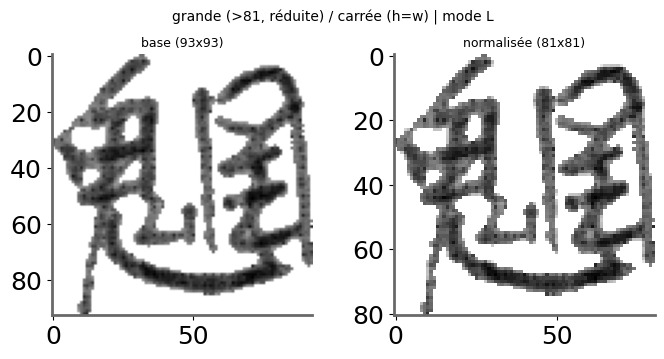

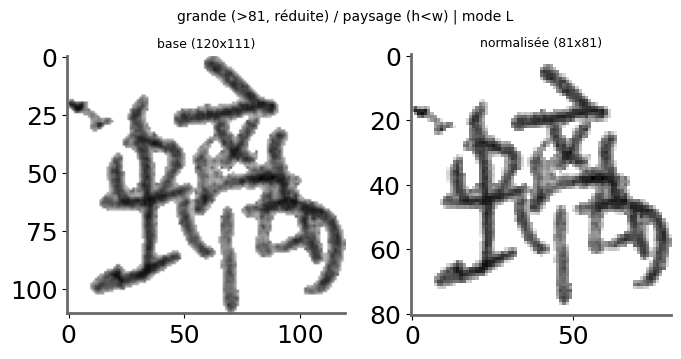

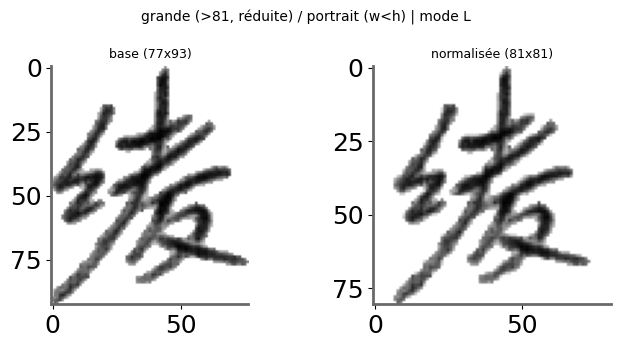

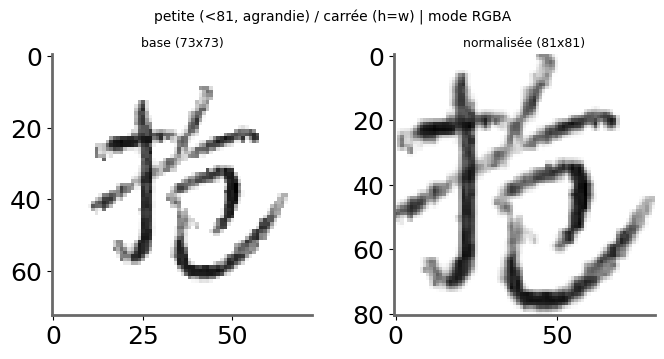

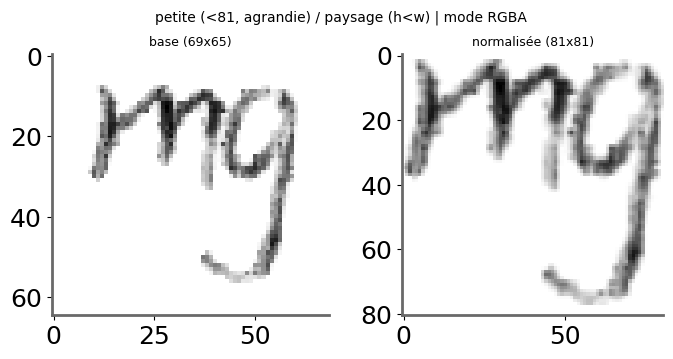

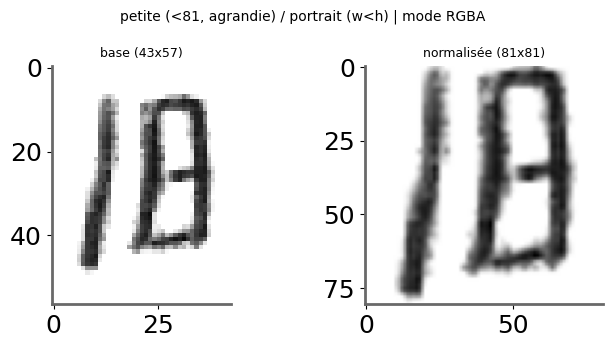

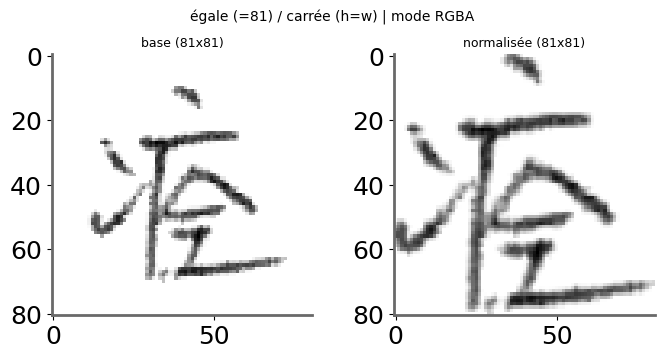

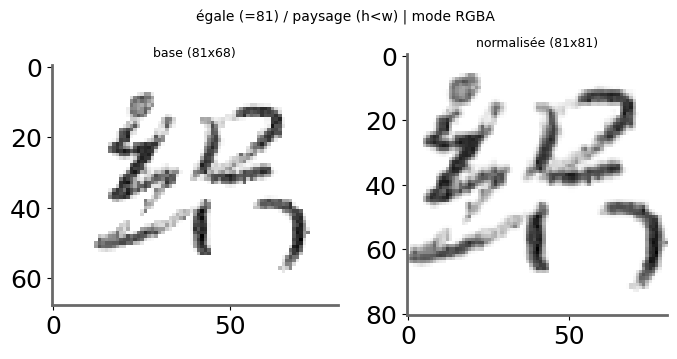

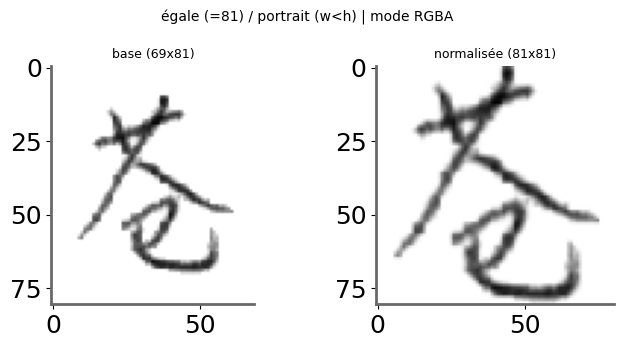

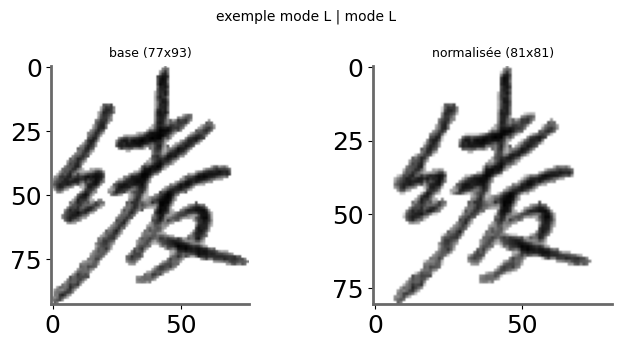

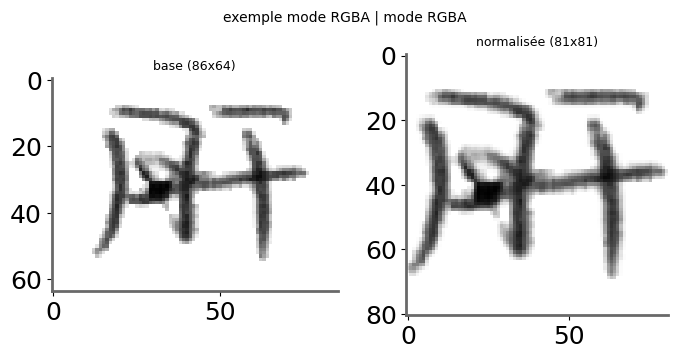

In [18]:
def show_case(title, path):
    base = np.asarray(Image.open(path).convert("L"))
    norm = normalise_images_pil(path)
    with Image.open(path) as im:
        mode = im.mode
    fig, axs = plt.subplots(1, 2, figsize=(7, 3.5))
    for ax, im_, t in zip(axs, (base, norm), ("base", "normalisée")):
        h, w = im_.shape
        ax.imshow(im_, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{t} ({w}x{h})", fontsize=9)
    fig.suptitle(f"{title} | mode {mode}", fontsize=10)
    plt.tight_layout()
    plt.show()

for (t, o), (i, p) in sorted(found.items()):
    show_case(f"{t} / {o}", p)

# Un exemple par mode (RGB, RGBA, L, P...)
for mode, (i, p) in mode_example.items():
    show_case(f"exemple mode {mode}", p)

In [19]:
# class img:
#     label
#     pixelsmatrice
    
# BATCH = 5000
# workers = .. ?
# workers.
#     for samples in train_dataset[batch]
#         img = sample.opencv2()
#         img = normalisevs2(immg)
#         img.pixelsmatrice = img.reversegrayscale 255 -> 0; 0-> 255
#         img.label = img.label
#         npy.write(BATCH)
#         Progressbar
    
# => batch 5000 write sur npy avec cat en inversant les couleurs peut etre faire ça avant dans le dataloader sur lequel on va iterer 

In [20]:
from dataclasses import dataclass
@dataclass
class Img:
    label: int
    pixels: np.ndarray | None          # (81, 81) uint8, None si l'image est illisible

def normalise_image_and_inverse_colors(sample):
    path, label = sample
    arr = normalise_images_cv2(path)   
    if arr is None:
        return Img(label, None)
    return Img(label, 255 - arr)


In [21]:
import numpy as np
from tqdm.auto import tqdm

def save_dataset(dataset, name, img_size):
    """
    Traite et enregistre les images et les targets d'un dataset au format Numpy.
    Utilise np.memmap pour ne pas saturer la RAM.
    """
    num_samples = len(dataset.samples)
    
    # 1. Création du fichier memmap pour les images (X)
    X = np.lib.format.open_memmap(
        f"{name}_x.npy", 
        mode="w+", 
        dtype=np.uint8, 
        shape=(num_samples, img_size, img_size)
    )
    
    failed_indices = []

    # 2. Traitement des images
    for i, sample in enumerate(tqdm(dataset.samples, desc=f"Génération {name}")):
        img = normalise_image_and_inverse_colors(sample)
        
        if img.pixels is not None:
            X[i] = img.pixels
        else:
            X[i] = 0  # Image noire par défaut
            failed_indices.append(i)

    # 3. Sauvegarde sur le disque
    X.flush()
    del X  # Ferme proprement le memmap
    
    # Sauvegarde directe des targets (au lieu de img.label qui échouait)
    Y = np.array(dataset.targets, dtype=np.int64)
    np.save(f"{name}_y.npy", Y)
    
    # Sauvegarde des échecs
    np.save(f"{name}_failed.npy", np.array(failed_indices, dtype=np.int64))

    # Bilan
    print(f" {name.capitalize()} terminé : {num_samples} images | {len(failed_indices)} échecs")

# --- Utilisation ---
SIZE = 81 # (Ou la taille de tes images)
save_dataset(train_dataset, "train_2", SIZE)
save_dataset(test_dataset, "test_2", SIZE)

Génération train_2:   0%|          | 0/3223042 [00:00<?, ?it/s]

 Train_2 terminé : 3223042 images | 0 échecs


Génération test_2:   0%|          | 0/776523 [00:00<?, ?it/s]

 Test_2 terminé : 776523 images | 0 échecs


In [3]:
y = np.load("test_2_y.npy")
print(y.shape, y.dtype, y.min(), y.max())
print(y[:456])

x = np.load("test_2_x.npy", mmap_mode="r")
print(x.shape, x.dtype)
print(x[:1,5])
assert len(x) == len(y)

failed = np.load("test_2_failed.npy")
print(len(failed), "échecs")

(776523,) int64 0 7329
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2]
(776523, 81, 81) uint8
[[  0   0   0   0   0   0   

In [7]:
# Reseau de neuronne

#Conv
# input shape : 81 * 81 donc modulo 9 modulo 3 donc on va faire du 3x3 

#Maxpooling : 
# Nout = floor((Nin -F +2P) / S) + 1

# N-3+1 * N-3+1 * 1
# padding 2 => N*N*1

class CNNHanzi_3x3(nn.Module):
    
    def __init__(self,num_class=10):
        super().__init__()
        self.num_class=num_class
        self.model = nn.Sequential(
            
            # first convolution  
            nn.Conv2d(in_channels=1, out_channels=64, kernel_size=3, stride=1, padding=1),            
            nn.ReLU(),
            # dim = (81 - 3 + 2)/1 + 1 = 81 => 81 x 81 x 64
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim : pareil
            nn.MaxPool2d((3,3),stride=3,padding=0),  
            # dim = floor(81 - 3) / 3) + 1 = 27 * 27 * 64
            nn.Dropout2d(0.2),            # Combat overfitting
            
            # second convolution  
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim = (27 - 3 + 2) / 1 + 1 = 27
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim : pareil
            nn.MaxPool2d((3,3),stride=3,padding=0),  
            # dim = 27 - 3 / 3 => 8 + 1 = 9
            nn.Dropout2d(0.2),            # Combat overfitting

            # troisième convolution  
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim = (9 - 3 + 2) / 1 + 1 = 9
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim : pareil
            nn.Dropout2d(0.2),   # Combat overfitting
            nn.AdaptiveAvgPool2d(3),             # ou nn.MaxPool2d(3) : 256×3×3
            nn.Flatten(),                 # convert feature map into feature vectors
            # MLP network   
            nn.Linear(256*3*3,1024),
            nn.ReLU(),
            nn.Dropout1d(0.2),            # Combat overfitting
            nn.Linear(1024, 7330),    # logits outpout
        )
        
    def forward(self, x):
        x=self.model(x)                   # forward pass
        return x

In [6]:
import torch
import torch.nn as nn#Optimised v
def conv_bn_relu(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),  # bias inutile avant BN
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True)]

class CNNHanzi_3x3(nn.Module):
    def __init__(self, num_class=7330):
        super().__init__()
        self.num_class = num_class
        self.model = nn.Sequential(
            *conv_bn_relu(1, 64),            # 64 x 81 x 81
            *conv_bn_relu(64, 64),
            nn.MaxPool2d(3),                 # 64 x 27 x 27
            nn.Dropout2d(0.1),

            *conv_bn_relu(64, 128),          # 128 x 27 x 27
            *conv_bn_relu(128, 128),
            nn.MaxPool2d(3),                 # 128 x 9 x 9
            nn.Dropout2d(0.1),

            *conv_bn_relu(128, 256),         # 256 x 9 x 9
            *conv_bn_relu(256, 256),
            nn.MaxPool2d(3),                 # 256 x 3 x 3
            nn.Flatten(),                    # 2304

            nn.Linear(256*3*3, 1024, bias=False),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(1024, num_class),      # logits
        )

    def forward(self, x):
        return self.model(x)

In [5]:
#FIDLE
# def fit(model,X_train,Y_train,X_test,Y_test, EPOCHS = 5, BATCH_SIZE = 32):
    
#     loss = nn.CrossEntropyLoss()
#     optimizer = torch.optim.Adam(model.parameters(),lr=1e-3) #lr is the learning rate
#     model.train()
    
#     history=convergence_history_CrossEntropyLoss()
    
#     history.update(model,X_train,Y_train,X_test,Y_test)
    
#     n=X_train.shape[0] #number of observations in the training data
    
#     #stochastic gradient descent
#     for epoch in range(EPOCHS):
        
#         batch_start=0
#         epoch_shuffler=np.arange(n) 
#         np.random.shuffle(epoch_shuffler) #remark that 'utilsData.DataLoader' could be used instead
        
#         while batch_start+BATCH_SIZE < n:
#             #get mini-batch observation
#             mini_batch_observations = epoch_shuffler[batch_start:batch_start+BATCH_SIZE]
#             var_X_batch = Variable(X_train[mini_batch_observations,:,:]).float() #the input image is flattened
#             var_Y_batch = Variable(Y_train[mini_batch_observations])
            
#             #gradient descent step
#             optimizer.zero_grad()               #set the parameters gradients to 0
#             Y_pred_batch = model(var_X_batch)   #predict y with the current NN parameters
            
#             curr_loss = loss(Y_pred_batch, var_Y_batch)  #compute the current loss
#             curr_loss.backward()                         #compute the loss gradient w.r.t. all NN parameters
#             optimizer.step()                             #update the NN parameters
            
#             #prepare the next mini-batch of the epoch
#             batch_start+=BATCH_SIZE
            
#         history.update(model,X_train,Y_train,X_test,Y_test)
    
#     return history



In [6]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import time
from tqdm.auto import tqdm


class MemmapHanzi(Dataset):
    def __init__(self, x_path, y_path, idx=None):
        self.x_path, self.y_path = x_path, y_path
        self.x, self.y_full = None, None

        y = np.load(y_path)
        self.idx = idx if idx is not None else np.arange(len(y))
        self.y = torch.from_numpy(y[self.idx]).long()

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        if self.x is None:
            self.x = np.load(self.x_path, mmap_mode="r")

        real_i = self.idx[i]

        img = torch.from_numpy(
            np.array(self.x[real_i])
        ).unsqueeze(0)  # (1,81,81) uint8

        return img, self.y[i]


# --- split train/val sans dupliquer les 21 Go ---
y_all = np.load("test_2_y.npy")
n = len(y_all)

rng = np.random.default_rng(0)
perm = rng.permutation(n)

n_val = int(0.05 * n)
val_idx, train_idx = perm[:n_val], perm[n_val:]


train_ds = MemmapHanzi(
    "test_2_x.npy",
    "test_2_y.npy",
    train_idx
)

val_ds = MemmapHanzi(
    "test_2_x.npy",
    "test_2_y.npy",
    val_idx
)


train_loader = DataLoader(
    train_ds,
    batch_size=512,
    shuffle=True,
    num_workers=0,
    persistent_workers=True,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=512,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


def evaluate(model, loader):
    model.eval()

    correct = 0
    total = 0
    loss_sum = 0.0

    lossf = nn.CrossEntropyLoss()

    pbar = tqdm(
        loader,
        desc="Validation",
        unit="batch",
        leave=False
    )

    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):

        for xb, yb in pbar:

            xb = (
                xb.cuda(non_blocking=True)
                .float()
                .div_(255)
                .contiguous(memory_format=torch.channels_last)
            )

            yb = yb.cuda(non_blocking=True)

            out = model(xb)

            loss = lossf(out, yb)

            loss_sum += loss.item() * yb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.size(0)

            pbar.set_postfix(
                loss=f"{loss.item():.4f}",
                acc=f"{correct / total:.4f}"
            )

    model.train()

    return loss_sum / total, correct / total


def fit(
    model,
    train_loader,
    val_loader,
    epochs=5,
    lr=1e-3,
    ckpt_path="hanzi_cnn_gros.pt"
):

    torch.backends.cudnn.benchmark = True

    model = model.cuda().to(memory_format=torch.channels_last)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=lr
    )

    scaler = torch.amp.GradScaler()
    lossf = nn.CrossEntropyLoss()

    best_acc = 0.0

    for epoch in range(epochs):

        t0 = time.time()

        # Reset du compteur de pic VRAM
        torch.cuda.reset_peak_memory_stats()

        pbar = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}",
            unit="batch"
        )

        for xb, yb in pbar:

            xb = (
                xb.cuda(non_blocking=True)
                .float()
                .div_(255)
                .contiguous(memory_format=torch.channels_last)
            )

            yb = yb.cuda(non_blocking=True)

            opt.zero_grad(set_to_none=True)

            with torch.autocast("cuda", dtype=torch.float16):
                loss = lossf(model(xb), yb)

            # Backward
            scaler.scale(loss).backward()

            # Optimizer
            scaler.step(opt)
            scaler.update()

            # VRAM actuelle
            vram = torch.cuda.memory_allocated() / 1024**3

            # Pic VRAM depuis le début de l'epoch
            peak_vram = torch.cuda.max_memory_allocated() / 1024**3

            pbar.set_postfix(
                loss=f"{loss.item():.4f}",
                vram=f"{vram:.2f}G",
                peak=f"{peak_vram:.2f}G"
            )

        # --- validation ---
        val_loss, val_acc = evaluate(
            model,
            val_loader
        )

        epoch_time = time.time() - t0

        peak_vram = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"val_loss={val_loss:.4f} | "
            f"val_acc={val_acc:.4f} | "
            f"peak VRAM={peak_vram:.2f} GB | "
            f"temps={epoch_time:.0f}s"
        )

        # --- sauvegarde du meilleur modèle ---
        if val_acc > best_acc:

            best_acc = val_acc

            torch.save(
                {
                    "model": model.state_dict(),
                    "epoch": epoch,
                    "val_acc": val_acc
                },
                ckpt_path
            )

            print(
                f"  ✓ meilleur modèle sauvegardé "
                f"(acc={val_acc:.4f})"
            )

    return model


# --- modèle ---
model = CNNHanzi_3x3(7330)

model = fit(
    model,
    train_loader,
    val_loader,
    epochs=5,
    lr=1e-3
)

Epoch 1/5:   0%|          | 0/1440 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [9]:
from torch.utils.data import IterableDataset
import time
import numpy as np
import torch
import torch.nn as nn
import torch.multiprocessing as mp
from torch.utils.data import IterableDataset, DataLoader
import math
import time
from tqdm.auto import tqdm
class ChunkedHanziDataset(IterableDataset):
    def __init__(self, x_path, y_path, chunk_size=100_000, shuffle=True):
        self.x_path = x_path
        self.y_path = y_path
        self.chunk_size = chunk_size
        self.shuffle = shuffle
        
        # On lit juste la structure pour connaître la taille totale
        mmap_x = np.load(self.x_path, mmap_mode="r")
        self.total_samples = len(mmap_x)
        del mmap_x

    def __iter__(self):
        worker_info = torch.utils.data.get_worker_info()
        
        # 1. Gestion du multi-processing (num_workers > 0)
        if worker_info is None:
            start_idx, end_idx = 0, self.total_samples
        else:
            # Répartition équitable du dataset entre les workers
            per_worker = int(math.ceil(self.total_samples / float(worker_info.num_workers)))
            start_idx = worker_info.id * per_worker
            end_idx = min(start_idx + per_worker, self.total_samples)

        # Chaque worker ouvre son propre accès mmap
        x_mmap = np.load(self.x_path, mmap_mode='r')
        y_mmap = np.load(self.y_path, mmap_mode='r')

        # 2. Découpage de la portion du worker en chunks
        chunk_starts = list(range(start_idx, end_idx, self.chunk_size))
        
        if self.shuffle:
            np.random.shuffle(chunk_starts) # Mélange l'ordre d'appel des chunks

        for c_start in chunk_starts:
            c_end = min(c_start + self.chunk_size, end_idx)

            # 3. LECTURE SÉQUENTIELLE : On force la copie du mmap vers la RAM
            x_chunk = np.array(x_mmap[c_start:c_end])
            y_chunk = np.array(y_mmap[c_start:c_end])

            # 4. SHUFFLE EN RAM : Ne touche plus au disque
            if self.shuffle:
                indices = np.arange(len(x_chunk))
                np.random.shuffle(indices)
                x_chunk = x_chunk[indices]
                y_chunk = y_chunk[indices]

            # 5. Distribution des tensors
            for i in range(len(x_chunk)):
                img = torch.from_numpy(x_chunk[i]).unsqueeze(0) # (1, 81, 81) uint8
                label = torch.tensor(y_chunk[i], dtype=torch.long)
                yield img, label

# --- Entraînement ---
# chunk_size=100_000 images = ~656 Mo par worker. 
# Avec 4 workers, cela consommera ~2.6 Go de RAM, ce qui est parfait pour vos 16 Go.
train_ds = ChunkedHanziDataset("train_2_x.npy", "train_2_y.npy", chunk_size=100_000, shuffle=True)

train_loader = DataLoader(
    train_ds,
    batch_size=1024,
    pin_memory=True,
    drop_last=True,
    # Ne mettez PAS shuffle=True ou sampler ici
)

# --- Validation ---
# Pas besoin de shuffle pour la validation, lecture strictement séquentielle
test_ds = ChunkedHanziDataset("test_2_x.npy", "test_2_y.npy", chunk_size=100_000, shuffle=False)

val_loader = DataLoader(
    test_ds,
    batch_size=1024,
    pin_memory=True,
)

def evaluate(model, loader):
    model.eval()

    correct = 0
    total = 0
    loss_sum = 0.0

    lossf = nn.CrossEntropyLoss()

    pbar = tqdm(
        loader,
        desc="Validation",
        unit="batch",
        leave=False
    )

    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):

        for xb, yb in pbar:

            xb = (
                xb.cuda(non_blocking=True)
                .float()
                .div_(255)
                .contiguous(memory_format=torch.channels_last)
            )

            yb = yb.cuda(non_blocking=True)

            out = model(xb)

            loss = lossf(out, yb)

            loss_sum += loss.item() * yb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.size(0)

            pbar.set_postfix(
                loss=f"{loss.item():.4f}",
                acc=f"{correct / total:.4f}"
            )

    model.train()

    return loss_sum / total, correct / total


def fit(
    model,
    train_loader,
    val_loader,
    epochs=5,
    lr=1e-3,
    ckpt_path="hanzi_cnn_2.pt"
    ):

    torch.backends.cudnn.benchmark = True

    model = model.cuda().to(memory_format=torch.channels_last)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=lr
    )

    scaler = torch.amp.GradScaler()
    lossf = nn.CrossEntropyLoss()

    best_acc = 0.0

    for epoch in range(epochs):

        t0 = time.time()

        # Reset du compteur de pic VRAM
        torch.cuda.reset_peak_memory_stats()

        pbar = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}",
            unit="batch"
        )

        for xb, yb in pbar:

            xb = (
                xb.cuda(non_blocking=True)
                .float()
                .div_(255)
                .contiguous(memory_format=torch.channels_last)
            )

            yb = yb.cuda(non_blocking=True)

            opt.zero_grad(set_to_none=True)

            with torch.autocast("cuda", dtype=torch.float16):
                loss = lossf(model(xb), yb)

            # Backward
            scaler.scale(loss).backward()

            # Optimizer
            scaler.step(opt)
            scaler.update()

            # VRAM actuelle
            vram = torch.cuda.memory_allocated() / 1024**3

            # Pic VRAM depuis le début de l'epoch
            peak_vram = torch.cuda.max_memory_allocated() / 1024**3

            pbar.set_postfix(
                loss=f"{loss.item():.4f}",
                vram=f"{vram:.2f}G",
                peak=f"{peak_vram:.2f}G"
            )

        # --- validation ---
        val_loss, val_acc = evaluate(
            model,
            val_loader
        )

        epoch_time = time.time() - t0

        peak_vram = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"val_loss={val_loss:.4f} | "
            f"val_acc={val_acc:.4f} | "
            f"peak VRAM={peak_vram:.2f} GB | "
            f"temps={epoch_time:.0f}s"
        )

        # --- sauvegarde du meilleur modèle ---
        if val_acc > best_acc:

            best_acc = val_acc

            torch.save(
                {
                    "model": model.state_dict(),
                    "epoch": epoch,
                    "val_acc": val_acc
                },
                ckpt_path
            )

            print(
                f"  ✓ meilleur modèle sauvegardé "
                f"(acc={val_acc:.4f})"
            )

    return model


# --- modèle ---
model = CNNHanzi_3x3(7330)

model = fit(
    model,
    train_loader,
    val_loader,
    epochs=5,
    lr=1e-3
)

Epoch 1/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 1/5 | val_loss=10.3096 | val_acc=0.0314 | peak VRAM=6.66 GB | temps=2243s
  ✓ meilleur modèle sauvegardé (acc=0.0314)


Epoch 2/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 2/5 | val_loss=8.7193 | val_acc=0.0472 | peak VRAM=5.07 GB | temps=1702s
  ✓ meilleur modèle sauvegardé (acc=0.0472)


Epoch 3/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 3/5 | val_loss=4.0475 | val_acc=0.2147 | peak VRAM=5.07 GB | temps=1720s
  ✓ meilleur modèle sauvegardé (acc=0.2147)


Epoch 4/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 4/5 | val_loss=3.1448 | val_acc=0.3907 | peak VRAM=5.07 GB | temps=1724s
  ✓ meilleur modèle sauvegardé (acc=0.3907)


Epoch 5/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 5/5 | val_loss=2.7224 | val_acc=0.4726 | peak VRAM=5.07 GB | temps=1722s
  ✓ meilleur modèle sauvegardé (acc=0.4726)


In [14]:
# --- modèle ---
model = CNNHanzi_3x3(7330)

# --- charger le meilleur checkpoint précédent ---
checkpoint = torch.load(
    "hanzi_cnn_3.pt",
    map_location="cuda"
)

model.load_state_dict(checkpoint["model"])


<All keys matched successfully>

In [15]:
print(
    f"Checkpoint chargé : "
    f"epoch={checkpoint['epoch'] + 1}, "
    f"val_acc={checkpoint['val_acc']:.4f}"
)

model = fit(
    model,
    train_loader,
    val_loader,
    epochs=25,
    lr=1e-4,
    ckpt_path="hanzi_cnn_4.pt",
)


Checkpoint chargé : epoch=1, val_acc=0.7386


Epoch 1/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 1/25 | val_loss=1.0307 | val_acc=0.7613 | peak VRAM=5.07 GB | temps=1670s
  ✓ meilleur modèle sauvegardé (acc=0.7613)


Epoch 2/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 2/25 | val_loss=1.0342 | val_acc=0.7626 | peak VRAM=5.07 GB | temps=1668s
  ✓ meilleur modèle sauvegardé (acc=0.7626)


Epoch 3/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 3/25 | val_loss=0.9826 | val_acc=0.7740 | peak VRAM=5.07 GB | temps=1669s
  ✓ meilleur modèle sauvegardé (acc=0.7740)


Epoch 4/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 4/25 | val_loss=0.9889 | val_acc=0.7756 | peak VRAM=5.07 GB | temps=1660s
  ✓ meilleur modèle sauvegardé (acc=0.7756)


Epoch 5/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 5/25 | val_loss=1.3884 | val_acc=0.7292 | peak VRAM=5.07 GB | temps=1642s


Epoch 6/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 6/25 | val_loss=1.2197 | val_acc=0.7282 | peak VRAM=5.07 GB | temps=1660s


Epoch 7/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 7/25 | val_loss=0.9998 | val_acc=0.7772 | peak VRAM=5.07 GB | temps=1666s
  ✓ meilleur modèle sauvegardé (acc=0.7772)


Epoch 8/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:01, ?batch/s]

Epoch 8/25 | val_loss=0.9934 | val_acc=0.7712 | peak VRAM=5.07 GB | temps=1651s


Epoch 9/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 9/25 | val_loss=1.0524 | val_acc=0.7663 | peak VRAM=5.07 GB | temps=1656s


Epoch 10/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 10/25 | val_loss=1.0408 | val_acc=0.7714 | peak VRAM=5.07 GB | temps=1655s


Epoch 11/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 11/25 | val_loss=1.3511 | val_acc=0.7364 | peak VRAM=5.07 GB | temps=1650s


Epoch 12/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 12/25 | val_loss=1.2753 | val_acc=0.7560 | peak VRAM=5.07 GB | temps=1651s


Epoch 13/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 13/25 | val_loss=0.9827 | val_acc=0.7785 | peak VRAM=5.07 GB | temps=1656s
  ✓ meilleur modèle sauvegardé (acc=0.7785)


Epoch 14/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 14/25 | val_loss=1.3297 | val_acc=0.7332 | peak VRAM=5.07 GB | temps=1651s


Epoch 15/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 15/25 | val_loss=1.1360 | val_acc=0.7647 | peak VRAM=5.07 GB | temps=1666s


Epoch 16/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 16/25 | val_loss=1.2499 | val_acc=0.7496 | peak VRAM=5.07 GB | temps=1662s


Epoch 17/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 17/25 | val_loss=1.0331 | val_acc=0.7757 | peak VRAM=5.07 GB | temps=1651s


Epoch 18/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 18/25 | val_loss=1.3189 | val_acc=0.7438 | peak VRAM=5.07 GB | temps=1661s


Epoch 19/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 19/25 | val_loss=1.1504 | val_acc=0.7659 | peak VRAM=5.07 GB | temps=1648s


Epoch 20/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 20/25 | val_loss=1.1973 | val_acc=0.7548 | peak VRAM=5.07 GB | temps=1655s


Epoch 21/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 21/25 | val_loss=1.5505 | val_acc=0.7074 | peak VRAM=5.07 GB | temps=1658s


Epoch 22/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 22/25 | val_loss=1.3525 | val_acc=0.7377 | peak VRAM=5.07 GB | temps=1645s


Epoch 23/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 23/25 | val_loss=1.1606 | val_acc=0.7682 | peak VRAM=5.07 GB | temps=1682s


Epoch 24/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 24/25 | val_loss=1.4756 | val_acc=0.7173 | peak VRAM=5.07 GB | temps=1726s


Epoch 25/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 25/25 | val_loss=1.6577 | val_acc=0.7012 | peak VRAM=5.07 GB | temps=1750s


In [7]:

torch.backends.cudnn.benchmark = True
model = CNNHanzi_3x3(7330).cuda().to(memory_format=torch.channels_last)
opt = torch.optim.AdamW(model.parameters(), 1e-3)
scaler = torch.amp.GradScaler()

for bs in [64, 128, 256, 512, 1024, 2048]:
    try:
        torch.cuda.reset_peak_memory_stats()
        x = torch.randn(bs, 1, 81, 81, device="cuda").contiguous(memory_format=torch.channels_last)
        y = torch.randint(0, 7330, (bs,), device="cuda")
        for i in range(25):
            if i == 5: torch.cuda.synchronize(); t = time.time()   # warm-up
            with torch.autocast("cuda", dtype=torch.float16):
                loss = torch.nn.functional.cross_entropy(model(x), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        torch.cuda.synchronize()
        print(f"bs {bs:5d} | {20*bs/(time.time()-t):6.0f} img/s | peak {torch.cuda.max_memory_allocated()/2**30:.2f} GB")
    except torch.cuda.OutOfMemoryError:
        print(f"bs {bs}: out of memory"); break

bs    64 |   3020 img/s | peak 1.25 GB
bs   128 |   3252 img/s | peak 2.11 GB
bs   256 |   3424 img/s | peak 3.69 GB
bs   512 |   3472 img/s | peak 2.96 GB
bs  1024 |   3508 img/s | peak 7.02 GB


[W1007 14:53:37.933245832 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1721761792 bytes (free: 96337920, total: 8220901376).
[W1007 14:53:39.819023873 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1721761792 bytes (free: 1480458240, total: 8220901376).
[W1007 14:53:39.819108903 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1721761792 bytes (free: 1480458240, total: 8220901376).


bs 2048: out of memory


In [ ]:
batch_size  = 512
epochs      = 128


history=fit(model,x_train,y_train,x_test,y_test,EPOCHS=epochs,BATCH_SIZE = batch_size)

In [ ]:
var_x_test = Variable(x_test[:,:,:]).float()
var_y_test = Variable(y_test[:])
y_pred = model(var_x_test)

loss = nn.CrossEntropyLoss()
curr_loss = loss(y_pred, var_y_test)

val_loss = curr_loss.item()
val_accuracy  = float( (torch.argmax(y_pred, dim= 1) == var_y_test).float().mean() )


print('Test loss     :', val_loss)
print('Test accuracy :', val_accuracy)

In [ ]:
fidle.scrawler.history(history, figsize=(6,4))

In [ ]:
y_pred = model(var_x_test)
np_y_pred_label = torch.argmax(y_pred, dim= 1).numpy().astype(np.uint8)

np_x_test=x_test.numpy().astype(np.float64)
np_y_test=y_test.numpy().astype(np.uint8)

fidle.scrawler.images(np_x_test, np_y_test, range(0,60), columns=12, x_size=1, y_size=1, y_pred=np_y_pred_label)

In [ ]:
errors=[ i for i in range(len(np_y_test)) if np_y_pred_label[i]!=np_y_test[i] ]
errors=errors[:min(24,len(errors))]
fidle.scrawler.images(np_x_test, np_y_test, errors[:15], columns=6, x_size=2, y_size=2, y_pred=np_y_pred_label)

In [ ]:
fidle.scrawler.confusion_matrix(np_y_test,np_y_pred_label, range(10))

<div class="todo">
    A few things you can do for fun:
    <ul>
        <li>Changing the network architecture (layers, number of neurons, etc.)</li>
        <li>Display a summary of the network</li>
        <li>Retrieve and display the softmax output of the network, to evaluate its "doubts".</li>
    </ul>
</div>